In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def load_image(image_path, grayscale=False):
    if grayscale:
        return cv2.imread(image_path, cv2.IMREAD_GRAYSCALE) if image_path else print("Image path is empty.")
    else:
        img = cv2.imread(image_path)
        return cv2.cvtColor(img, cv2.COLOR_BGR2RGB) if img is not None else print("Image not found or could not be loaded.")


def detect_and_describe_sift(image):
    
    sift = cv2.SIFT_create(
        contrastThreshold=0.04,
        edgeThreshold=10,
        sigma=1.6
    )

    kp, des = sift.detectAndCompute(image, None)

    return kp, des

# A function to find correspondences between two sets of keypoints and descriptors
'''CrossCheck e Lowe's ratio sono mutualmente esclusivi perchè CrossCheck forza ad usare bf.match
e quindi non permette di usare il KNN. Se si vuole usare il KNN, bisogna impostare cross_check=False.
In questo caso, si usa il KNN per trovare i due migliori match per ogni descrittore e poi si applica il test di Lowe's ratio.'''
def kp_matching_bf(des1, des2, norm_type=cv2.NORM_L2, cross_check=False, lowe_ratio=0.75):
    bf = cv2.BFMatcher(norm_type, crossCheck=cross_check)

    if cross_check:
        # Simple matching: only best match with crossCheck
        all_matches = bf.match(des1, des2)
        good_matches = sorted(all_matches, key=lambda x: x.distance)
    else:
        # KNN matching + Lowe's ratio test
        if len(des1) <= 1 or len(des2) <= 1:
            return [], []
        matches = bf.knnMatch(des1, des2, k=2)
        if matches is None or len(matches) == 0:
            return [], []
        all_matches = [] 
        good_matches = []
        for m, n in matches:
            all_matches.append(m)
            if m.distance < lowe_ratio * n.distance:
                good_matches.append(m)


    return all_matches, good_matches

# Find model object within scene image
def find_model_in_scene(kp_model, kp_scene, min_match_count, good_matches, method=cv2.RANSAC, ransacReprojThreshold=5.0):
    if len(good_matches) < min_match_count:
        return None, None

    src_pts = np.float32([kp_model[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
    dst_pts = np.float32([kp_scene[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)

    M, mask = cv2.findHomography(src_pts, dst_pts, method, ransacReprojThreshold)

    return M, mask


def perform_template_matching_rot_scale(scene_img, template_img, des_model, hysteresys_th, method=cv2.TM_CCOEFF_NORMED, angles=range(-6, 7, 2), scales=np.linspace(0.95, 1.05, 5)):

    low_threshold, high_threshold = hysteresys_th

    # Se le immagini sono a colori, convertile in scala di grigi
    if len(scene_img.shape) >= 3:
        scene_gray = cv2.cvtColor(scene_img, cv2.COLOR_BGR2GRAY)
    else:
        scene_gray = scene_img.copy()

    if len(template_img.shape) == 3:
        template_orig_gray = cv2.cvtColor(template_img, cv2.COLOR_BGR2GRAY)
    else:
        template_orig_gray = template_img.copy()

    best_match_val = -np.inf
    top_left_best = None
    best_w = None
    best_h = None

    for scale in scales:
        # Ridimensiona il template
        scaled_template = cv2.resize(template_orig_gray, None, fx=scale, fy=scale, interpolation=cv2.INTER_LINEAR)
        h0, w0 = scaled_template.shape[:2]

        for angle in angles:
            # Ruota il template scalato
            rot_mat = cv2.getRotationMatrix2D((w0 / 2, h0 / 2), angle, 1.0)
            rotated_template = cv2.warpAffine(scaled_template, rot_mat, (w0, h0), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0)

            # Salta se il template diventa più grande della scena
            if rotated_template.shape[0] > scene_gray.shape[0] or rotated_template.shape[1] > scene_gray.shape[1]:
                continue

            # Esegui il template matching
            result = cv2.matchTemplate(scene_gray, rotated_template, method)
            min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(result)

            if method in [cv2.TM_SQDIFF, cv2.TM_SQDIFF_NORMED]:
                match_val = -min_val  # Per coerenza, invertiamo SQDIFF
                top_left = min_loc
            else:
                match_val = max_val
                top_left = max_loc

            if match_val > best_match_val:
                best_match_val = match_val
                top_left_best = top_left
                best_w = w0
                best_h = h0

    # Compute corners of the current box
    bottom_right_best = (top_left_best[0] + best_w, top_left_best[1] + best_h)

    corners = np.array([
        [list(top_left_best)],
        [list((top_left_best[0], bottom_right_best[1]))],
        [list(bottom_right_best)],
        [list((bottom_right_best[0], top_left_best[1]))]
    ])

    matched = False
    detected = False
    if best_match_val >= high_threshold:
        matched = True
        detected = True
        print("Match found above highthreshold.")
    elif best_match_val < low_threshold:
        matched = False
        detected = False
        print(f"Value {best_match_val} below low threshold {low_threshold}. No match found.")
    else:
        matched = True
        current_box = extract_template_from_corners(scene_img, corners)
        kp_box, des_box = detect_and_describe_sift(current_box)
        if kp_box is None or des_box is None:
            return corners, best_match_val, False

        # Match descriptors of the box with the model
        all_matches, good_matches = kp_matching_bf(des_model, des_box, lowe_ratio=0.8)

        min_matches = int(0.11 * len(des_model))

        if len(good_matches) >= min_matches:
            detected = True
            print(f"New match found with {len(good_matches)}/{min_matches} good matches. Match value: {best_match_val}.")
        else:
            detected = False
            print(f"Not enough matches: {len(good_matches)}/{min_matches}. No match found. Match value: {best_match_val}.")

    if matched: # togliere matched  e fare il controllo corners ==  None
        return corners, best_match_val, detected
    else:
        return None, best_match_val, detected  # Nessun match sopra la soglia




def extract_template_from_corners(image, corners):

    # Assicura che corners sia nella forma corretta
    corners = corners.reshape(-1, 2).astype(np.int32)

    # Crea una maschera nera
    mask = np.zeros(image.shape[:2], dtype=np.uint8)

    # Disegna il poligono bianco sulla maschera
    cv2.fillPoly(mask, [corners], 255)

    # Applica la maschera all'immagine originale
    masked = cv2.bitwise_and(image, image, mask=mask)

    # Bounding rect per ritagliare solo la regione di interesse (senza bordi neri intorno)
    x, y, w, h = cv2.boundingRect(corners)
    cropped_region = masked[y:y+h, x:x+w]

    return cropped_region

def show_keypoints(image, keypoints):
    img_with_keypoints = cv2.drawKeypoints(image, keypoints, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    plt.figure(figsize=(10, 10))
    plt.imshow(img_with_keypoints)
    plt.axis('off')
    plt.show()

def show_correspondences(image1, image2, kp1, kp2, matches):
    img_matches = cv2.drawMatches(image1, kp1, image2, kp2, matches, None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    plt.figure(figsize=(15, 10))
    plt.imshow(img_matches)
    plt.axis('off')
    plt.show()

# Function to draw the bounding box around the detected model in the scene
def draw_bounding_box(img_scene, img_model, M):
    # Corners of the model image
    h, w = img_model.shape[:2]
    pts = np.float32([[0,0], [0,h-1], [w-1,h-1], [w-1,0]]).reshape(-1, 1, 2)

    # Project the corners into the scene image
    dst = cv2.perspectiveTransform(pts, M)

    # Draw the bounding box
    img_scene_with_box = cv2.polylines(img_scene, [np.int32(dst)], True, (255, 0, 0), 3, cv2.LINE_AA)

    return np.int32(dst), img_scene_with_box

def draw_matched_rectangle(image,corners):

    image_with_rectangle = image.copy()
    cv2.polylines(image_with_rectangle, [corners], True, (0, 255, 0), 2)
    return image_with_rectangle

# A function to remove the detected object from the scene image
def remove_object_from_scene(img_scene, corners):
    # Create a mask for the detected object
    mask = np.zeros(img_scene.shape[:2], dtype=np.uint8)
    cv2.fillPoly(mask, [corners], (255))

    # Invert the mask to keep the background
    mask_inv = cv2.bitwise_not(mask)

    # Remove the object from the scene image
    img_scene_no_object = cv2.bitwise_and(img_scene, img_scene, mask=mask_inv)

    return img_scene_no_object

In [3]:

def main(model_path, scene_path, 
         grayscale=False,
         min_match_pct=0.1,
         cross_check=False, 
         lowe_ratio=0.8, 
         hysteresys_th=(0.45, 0.8),
         method=cv2.RANSAC, 
         ransacReprojThreshold=5.0, 
         similarity_measure=cv2.TM_CCOEFF_NORMED):

    detections = 0

    model_img = load_image(model_path, grayscale=grayscale)
    scene_img = load_image(scene_path, grayscale=grayscale)

    scene = scene_img.copy()

    # Detect keypoints and descriptors
    kp_model, des_model = detect_and_describe_sift(model_img)
    kp_scene, des_scene = detect_and_describe_sift(scene_img)

    if kp_model is None or kp_scene is None:
        print("No keypoints or descriptors found in the model or scene image.")
        return

    # Match keypoints
    all_matches, good_matches = kp_matching_bf(des_model, des_scene, norm_type=cv2.NORM_L2, cross_check=cross_check, lowe_ratio=lowe_ratio)
    
    # Find homography
    min_match_count = int(min_match_pct * len(kp_model))
    M, mask = find_model_in_scene(kp_model, kp_scene, min_match_count, good_matches)
    if M is None:
        print("Homography could not be computed. No instances detected.")
        return
    else:
        print(f"Homography computed successfully")
    
    detections += 1

    # Draw bounding box around the detected model in the scene
    corners, img_scene_with_box = draw_bounding_box(scene, model_img, M)

    # Compute ROI from the corners
    # roi_scene = compute_roi(scene_img, corners)

    # Extract the template to permit template matching
    template = extract_template_from_corners(scene, corners)

    while True:
        # Mask the object detected
        scene_img = remove_object_from_scene(scene_img, corners)

        # Perform template matching in the ROI
        corners, match_val, detected = perform_template_matching_rot_scale(scene_img, template, des_model, hysteresys_th, method=similarity_measure)

        if corners is None:
            print(f"No match found during template matching on instance {detections+1}. Matching value: {match_val}/{hysteresys_th[0]}.")
            break

        if detected:
            detections += 1
            scene = draw_matched_rectangle(scene, corners)
        
    print(f"Total instances detected: {detections}")
    if detections > 0:
        plt.imshow(scene)
        plt.show()




--------------------------------- Processing scene 0 ---------------------------------
-------- Processing model 0 --------
Homography could not be computed. No instances detected.
-------- Processing model 1 --------
Homography could not be computed. No instances detected.
-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be computed. No instances detected.
-------- Processing model 4 --------
Homography could not be computed. No instances detected.
-------- Processing model 5 --------
Homography could not be computed. No instances detected.
-------- Processing model 6 --------
Homography could not be computed. No instances detected.
-------- Processing model 7 --------
Homography could not be computed. No instances detected.
-------- Processing model 8 --------
Homography could not be computed. No instances detected.
-------- Processing model 9 --------
Homography could not be comput

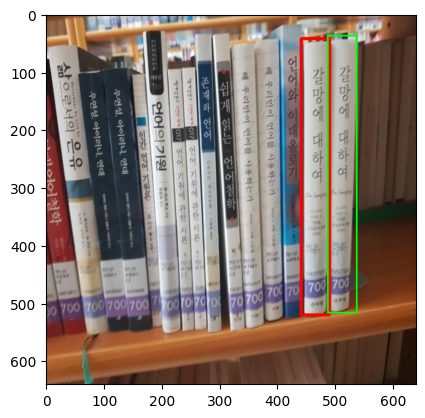

-------- Processing model 19 --------
Homography could not be computed. No instances detected.
-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 2 ---------------------------------
-------- Processing model 0 --------
Homography could not be computed. No instances detected.
-------- Processing model 1 --------
Homography could not be computed. No instances detected.
-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be computed. No instances detected.
-------- Processing model 4 --------
Homography could not be computed. No instances detected.
-------- Processing model 5 --------
Homography could not be computed. No instances detected.
-------- Processing model 6 --------
Homography could not be com

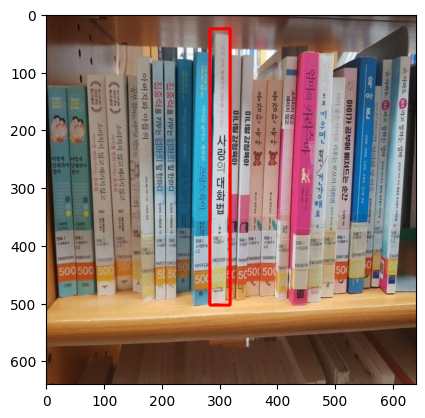

-------- Processing model 18 --------
Homography could not be computed. No instances detected.
-------- Processing model 19 --------
Homography could not be computed. No instances detected.
-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 3 ---------------------------------
-------- Processing model 0 --------
Homography could not be computed. No instances detected.
-------- Processing model 1 --------
Homography could not be computed. No instances detected.
-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be computed. No instances detected.
-------- Processing model 4 --------
Homography could not be computed. No instances detected.
-------- Processing model 5 --------
Homography could not be co

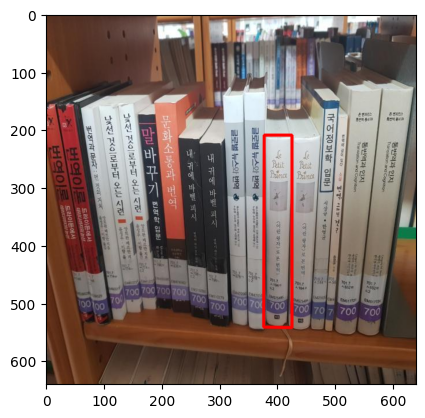

-------- Processing model 17 --------
Homography could not be computed. No instances detected.
-------- Processing model 18 --------
Homography could not be computed. No instances detected.
-------- Processing model 19 --------
Homography could not be computed. No instances detected.
-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 4 ---------------------------------
-------- Processing model 0 --------
Homography could not be computed. No instances detected.
-------- Processing model 1 --------
Homography could not be computed. No instances detected.
-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be computed. No instances detected.
-------- Processing model 4 --------
Homography could not be c

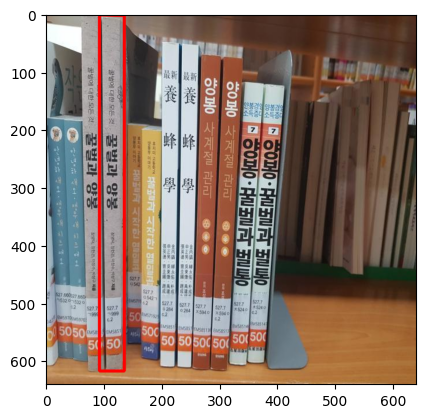

-------- Processing model 15 --------
Homography computed successfully
New match found with 114/87 good matches. Match value: 0.6240065097808838.
Value 0.5117744207382202 below low threshold 0.55. No match found.
No match found during template matching on instance 3. Matching value: 0.5117744207382202/0.55.
Total instances detected: 2


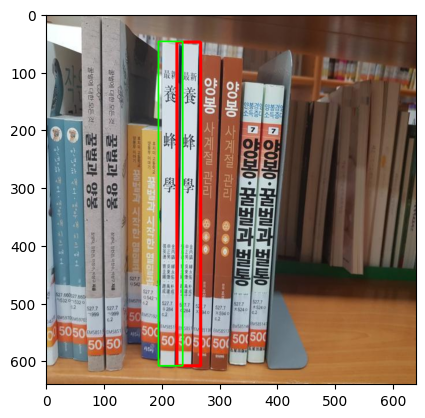

-------- Processing model 16 --------
Homography could not be computed. No instances detected.
-------- Processing model 17 --------
Homography could not be computed. No instances detected.
-------- Processing model 18 --------
Homography could not be computed. No instances detected.
-------- Processing model 19 --------
Homography could not be computed. No instances detected.
-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 5 ---------------------------------
-------- Processing model 0 --------
Homography could not be computed. No instances detected.
-------- Processing model 1 --------
Homography could not be computed. No instances detected.
-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be 

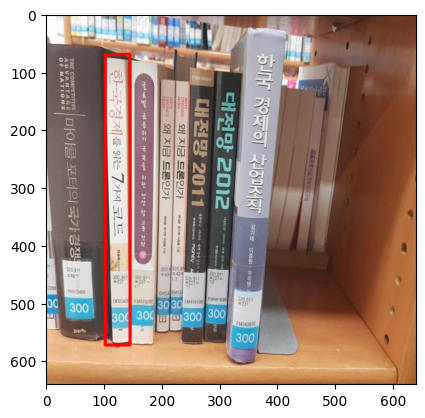

-------- Processing model 14 --------
Homography could not be computed. No instances detected.
-------- Processing model 15 --------
Homography could not be computed. No instances detected.
-------- Processing model 16 --------
Homography could not be computed. No instances detected.
-------- Processing model 17 --------
Homography could not be computed. No instances detected.
-------- Processing model 18 --------
Homography could not be computed. No instances detected.
-------- Processing model 19 --------
Homography could not be computed. No instances detected.
-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 6 ---------------------------------
-------- Processing model 0 --------
Homography could not be computed. No instances detected.
-------- Processing model 1 --------
Homography could not b

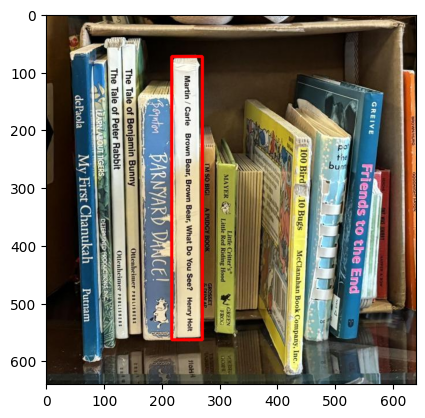

--------------------------------- Processing scene 7 ---------------------------------
-------- Processing model 0 --------
Homography could not be computed. No instances detected.
-------- Processing model 1 --------
Homography could not be computed. No instances detected.
-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be computed. No instances detected.
-------- Processing model 4 --------
Homography could not be computed. No instances detected.
-------- Processing model 5 --------
Homography could not be computed. No instances detected.
-------- Processing model 6 --------
Homography could not be computed. No instances detected.
-------- Processing model 7 --------
Homography could not be computed. No instances detected.
-------- Processing model 8 --------
Homography could not be computed. No instances detected.
-------- Processing model 9 --------
Homography could not be comput

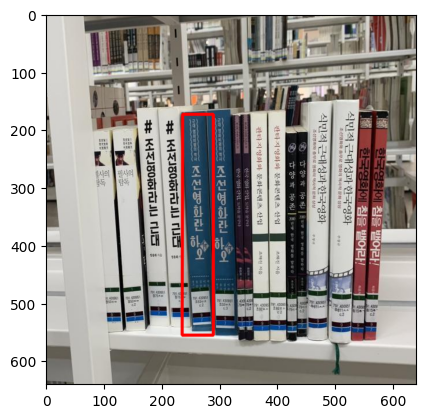

-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 8 ---------------------------------
-------- Processing model 0 --------
Homography could not be computed. No instances detected.
-------- Processing model 1 --------
Homography could not be computed. No instances detected.
-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be computed. No instances detected.
-------- Processing model 4 --------
Homography could not be computed. No instances detected.
-------- Processing model 5 --------
Homography could not be computed. No instances detected.
-------- Processing model 6 --------
Homography could not be computed. No instances detected.
-------- Processing model 7 --------
Homography could not be computed. No instances detected.
-------- Processing model 8 --------
Homography could not be compu

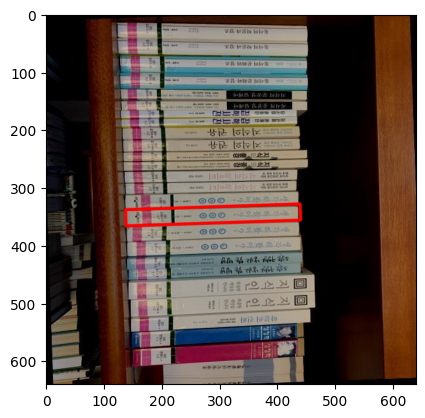

-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 10 ---------------------------------
-------- Processing model 0 --------
Homography could not be computed. No instances detected.
-------- Processing model 1 --------
Homography could not be computed. No instances detected.
-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be computed. No instances detected.
-------- Processing model 4 --------
Homography could not be computed. No instances detected.
-------- Processing model 5 --------
Homography could not be computed. No instances detected.
-------- Processing model 6 --------
Homography could not be computed. No instances detected.
-------- Processing model 7 --------
Homography could not be com

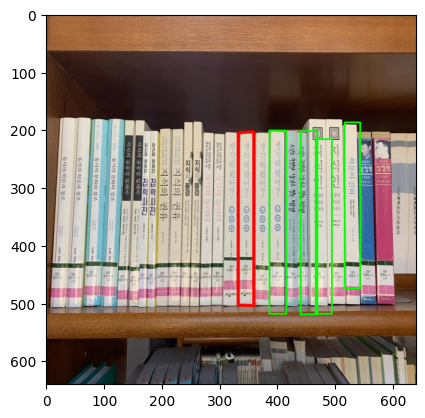

-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 11 ---------------------------------
-------- Processing model 0 --------
Homography could not be computed. No instances detected.
-------- Processing model 1 --------
Homography could not be computed. No instances detected.
-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be computed. No instances detected.
-------- Processing model 4 --------
Homography could not be computed. No instances detected.
-------- Processing model 5 --------
Homography could not be computed. No instances detected.
-------- Processing model 6 --------
Homography could not be computed. No instances detected.
-------- Processing model 7 --------
Homography could not be com

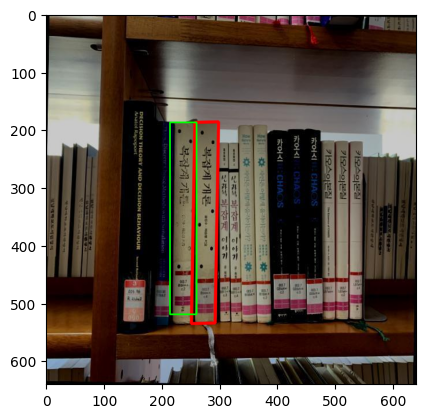

-------- Processing model 12 --------
Homography computed successfully
Not enough matches: 24/29. No match found. Match value: 0.7737558484077454.
Not enough matches: 21/29. No match found. Match value: 0.7500917315483093.
New match found with 31/29 good matches. Match value: 0.6105977296829224.
Not enough matches: 21/29. No match found. Match value: 0.5947022438049316.
Value 0.5410240888595581 below low threshold 0.55. No match found.
No match found during template matching on instance 3. Matching value: 0.5410240888595581/0.55.
Total instances detected: 2


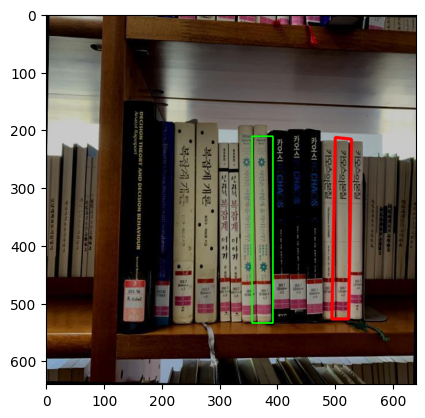

-------- Processing model 13 --------
Homography could not be computed. No instances detected.
-------- Processing model 14 --------
Homography could not be computed. No instances detected.
-------- Processing model 15 --------
Homography could not be computed. No instances detected.
-------- Processing model 16 --------
Homography could not be computed. No instances detected.
-------- Processing model 17 --------
Homography could not be computed. No instances detected.
-------- Processing model 18 --------
Homography could not be computed. No instances detected.
-------- Processing model 19 --------
Homography could not be computed. No instances detected.
-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 16 ---------------------------------
-------- Processing model 0 --------
Homography could not

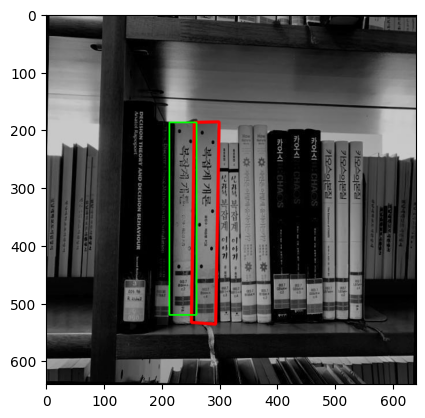

-------- Processing model 12 --------
Homography computed successfully
New match found with 29/29 good matches. Match value: 0.7775362730026245.
Not enough matches: 19/29. No match found. Match value: 0.7599360942840576.
Not enough matches: 22/29. No match found. Match value: 0.6213167905807495.
Not enough matches: 16/29. No match found. Match value: 0.6128644943237305.
Not enough matches: 12/29. No match found. Match value: 0.5732818245887756.
Value 0.5133917331695557 below low threshold 0.55. No match found.
No match found during template matching on instance 3. Matching value: 0.5133917331695557/0.55.
Total instances detected: 2


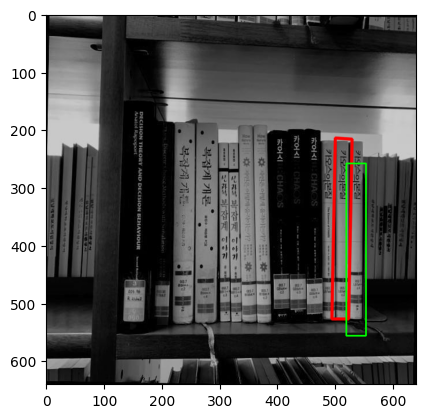

-------- Processing model 13 --------
Homography could not be computed. No instances detected.
-------- Processing model 14 --------
Homography could not be computed. No instances detected.
-------- Processing model 15 --------
Homography could not be computed. No instances detected.
-------- Processing model 16 --------
Homography could not be computed. No instances detected.
-------- Processing model 17 --------
Homography could not be computed. No instances detected.
-------- Processing model 18 --------
Homography could not be computed. No instances detected.
-------- Processing model 19 --------
Homography could not be computed. No instances detected.
-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 17 ---------------------------------
-------- Processing model 0 --------
Homography could not

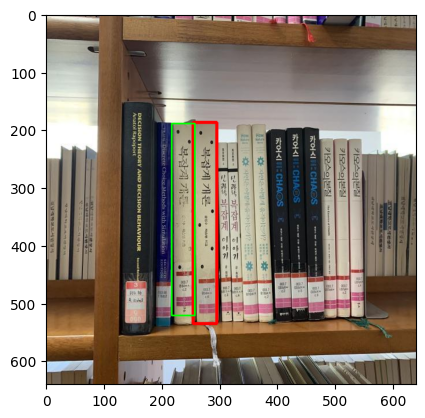

-------- Processing model 12 --------
Homography computed successfully
Not enough matches: 23/29. No match found. Match value: 0.7473474740982056.
Not enough matches: 21/29. No match found. Match value: 0.698650598526001.
Not enough matches: 17/29. No match found. Match value: 0.6532410383224487.
Not enough matches: 22/29. No match found. Match value: 0.6497730016708374.
Value 0.5339459776878357 below low threshold 0.55. No match found.
No match found during template matching on instance 2. Matching value: 0.5339459776878357/0.55.
Total instances detected: 1


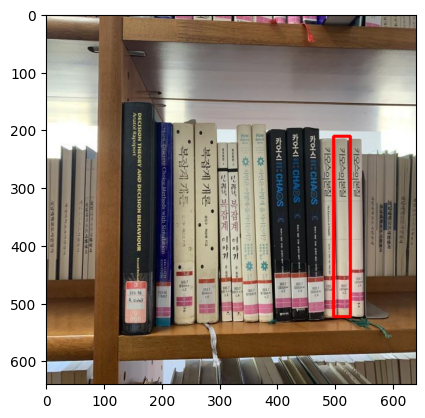

-------- Processing model 13 --------
Homography could not be computed. No instances detected.
-------- Processing model 14 --------
Homography could not be computed. No instances detected.
-------- Processing model 15 --------
Homography could not be computed. No instances detected.
-------- Processing model 16 --------
Homography could not be computed. No instances detected.
-------- Processing model 17 --------
Homography could not be computed. No instances detected.
-------- Processing model 18 --------
Homography could not be computed. No instances detected.
-------- Processing model 19 --------
Homography could not be computed. No instances detected.
-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 18 ---------------------------------
-------- Processing model 0 --------
Homography could not

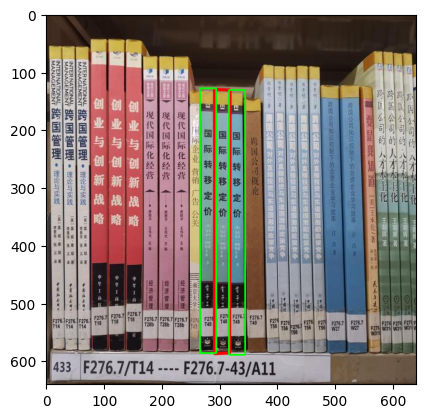

-------- Processing model 9 --------
Homography computed successfully
Match found above highthreshold.
Not enough matches: 48/52. No match found. Match value: 0.7520792484283447.
Not enough matches: 23/52. No match found. Match value: 0.5610314011573792.
Not enough matches: 31/52. No match found. Match value: 0.5908322930335999.
Not enough matches: 12/52. No match found. Match value: 0.6176066994667053.
Not enough matches: 23/52. No match found. Match value: 0.5623143315315247.
Value 0.521503210067749 below low threshold 0.55. No match found.
No match found during template matching on instance 3. Matching value: 0.521503210067749/0.55.
Total instances detected: 2


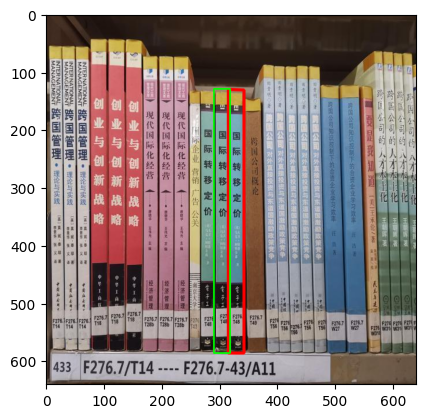

-------- Processing model 10 --------
Homography computed successfully
New match found with 103/52 good matches. Match value: 0.7969102263450623.
New match found with 96/52 good matches. Match value: 0.7713325023651123.
Value 0.4864306151866913 below low threshold 0.55. No match found.
No match found during template matching on instance 4. Matching value: 0.4864306151866913/0.55.
Total instances detected: 3


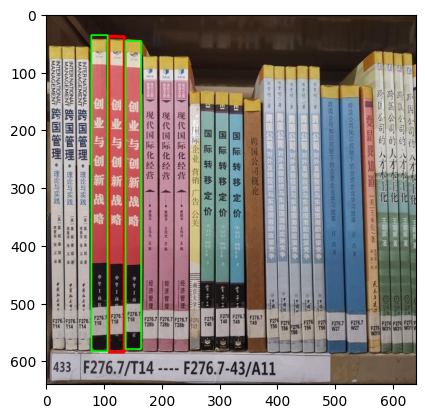

-------- Processing model 11 --------
Homography could not be computed. No instances detected.
-------- Processing model 12 --------
Homography could not be computed. No instances detected.
-------- Processing model 13 --------
Homography could not be computed. No instances detected.
-------- Processing model 14 --------
Homography could not be computed. No instances detected.
-------- Processing model 15 --------
Homography could not be computed. No instances detected.
-------- Processing model 16 --------
Homography could not be computed. No instances detected.
-------- Processing model 17 --------
Homography could not be computed. No instances detected.
-------- Processing model 18 --------
Homography could not be computed. No instances detected.
-------- Processing model 19 --------
Homography could not be computed. No instances detected.
-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography c

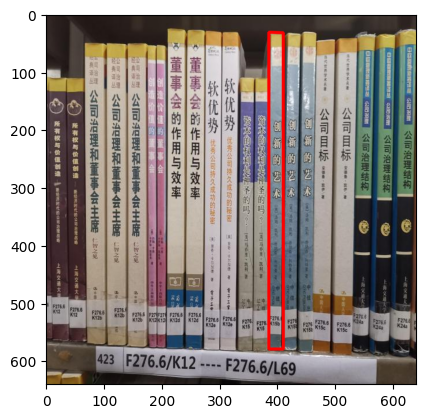

-------- Processing model 7 --------
Homography computed successfully
Not enough matches: 25/40. No match found. Match value: 0.6595531702041626.
Not enough matches: 23/40. No match found. Match value: 0.6549139022827148.
Not enough matches: 8/40. No match found. Match value: 0.6264526844024658.
Not enough matches: 22/40. No match found. Match value: 0.6321786046028137.
Not enough matches: 33/40. No match found. Match value: 0.6179759502410889.
New match found with 101/40 good matches. Match value: 0.611333966255188.
New match found with 42/40 good matches. Match value: 0.6070570349693298.
Not enough matches: 33/40. No match found. Match value: 0.5567545890808105.
Not enough matches: 35/40. No match found. Match value: 0.6449243426322937.
Value 0.4707537293434143 below low threshold 0.55. No match found.
No match found during template matching on instance 4. Matching value: 0.4707537293434143/0.55.
Total instances detected: 3


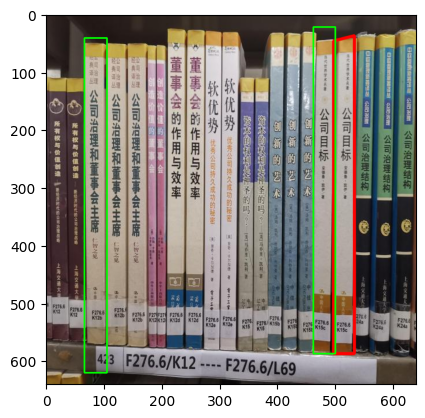

-------- Processing model 8 --------
Homography could not be computed. No instances detected.
-------- Processing model 9 --------
Homography could not be computed. No instances detected.
-------- Processing model 10 --------
Homography could not be computed. No instances detected.
-------- Processing model 11 --------
Homography could not be computed. No instances detected.
-------- Processing model 12 --------
Homography could not be computed. No instances detected.
-------- Processing model 13 --------
Homography could not be computed. No instances detected.
-------- Processing model 14 --------
Homography could not be computed. No instances detected.
-------- Processing model 15 --------
Homography could not be computed. No instances detected.
-------- Processing model 16 --------
Homography could not be computed. No instances detected.
-------- Processing model 17 --------
Homography could not be computed. No instances detected.
-------- Processing model 18 --------
Homography cou

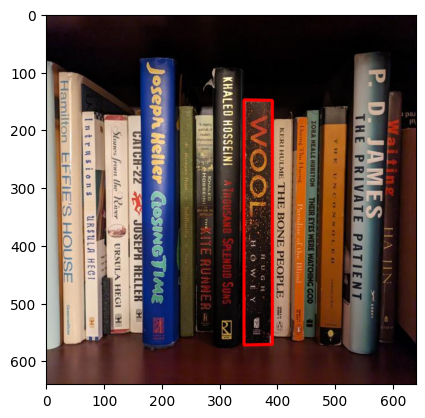

-------- Processing model 6 --------
Homography could not be computed. No instances detected.
-------- Processing model 7 --------
Homography could not be computed. No instances detected.
-------- Processing model 8 --------
Homography could not be computed. No instances detected.
-------- Processing model 9 --------
Homography could not be computed. No instances detected.
-------- Processing model 10 --------
Homography could not be computed. No instances detected.
-------- Processing model 11 --------
Homography could not be computed. No instances detected.
-------- Processing model 12 --------
Homography could not be computed. No instances detected.
-------- Processing model 13 --------
Homography could not be computed. No instances detected.
-------- Processing model 14 --------
Homography could not be computed. No instances detected.
-------- Processing model 15 --------
Homography could not be computed. No instances detected.
-------- Processing model 16 --------
Homography could

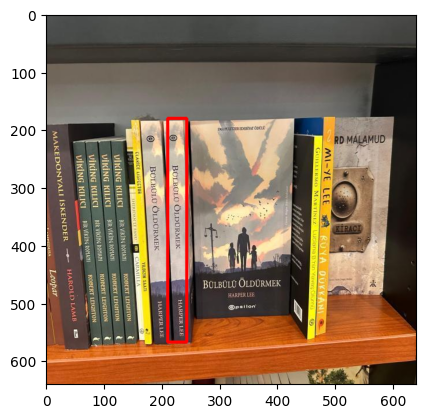

-------- Processing model 1 --------
Homography could not be computed. No instances detected.
-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be computed. No instances detected.
-------- Processing model 4 --------
Homography computed successfully
Value 0.45344507694244385 below low threshold 0.55. No match found.
No match found during template matching on instance 2. Matching value: 0.45344507694244385/0.55.
Total instances detected: 1


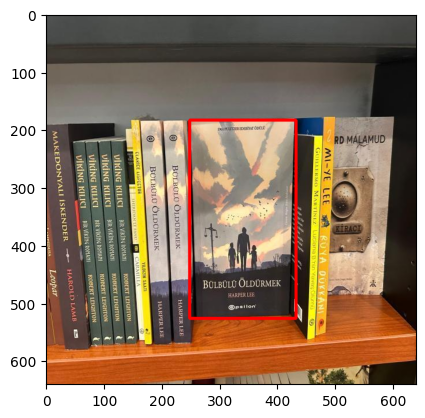

-------- Processing model 5 --------
Homography could not be computed. No instances detected.
-------- Processing model 6 --------
Homography could not be computed. No instances detected.
-------- Processing model 7 --------
Homography could not be computed. No instances detected.
-------- Processing model 8 --------
Homography could not be computed. No instances detected.
-------- Processing model 9 --------
Homography could not be computed. No instances detected.
-------- Processing model 10 --------
Homography could not be computed. No instances detected.
-------- Processing model 11 --------
Homography could not be computed. No instances detected.
-------- Processing model 12 --------
Homography could not be computed. No instances detected.
-------- Processing model 13 --------
Homography could not be computed. No instances detected.
-------- Processing model 14 --------
Homography could not be computed. No instances detected.
-------- Processing model 15 --------
Homography could 

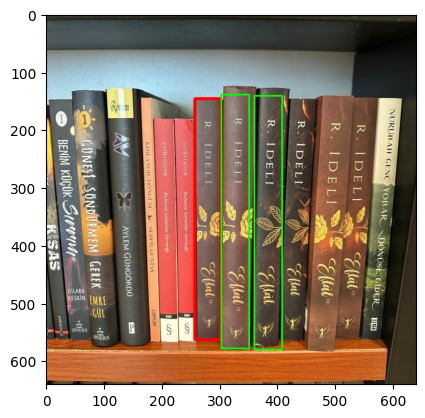

-------- Processing model 3 --------
Homography computed successfully
Not enough matches: 58/81. No match found. Match value: 0.5723296999931335.
Not enough matches: 55/81. No match found. Match value: 0.6260989904403687.
Value 0.5175715684890747 below low threshold 0.55. No match found.
No match found during template matching on instance 2. Matching value: 0.5175715684890747/0.55.
Total instances detected: 1


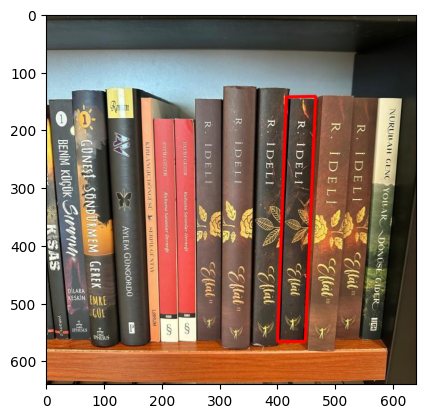

-------- Processing model 4 --------
Homography could not be computed. No instances detected.
-------- Processing model 5 --------
Homography could not be computed. No instances detected.
-------- Processing model 6 --------
Homography could not be computed. No instances detected.
-------- Processing model 7 --------
Homography could not be computed. No instances detected.
-------- Processing model 8 --------
Homography could not be computed. No instances detected.
-------- Processing model 9 --------
Homography could not be computed. No instances detected.
-------- Processing model 10 --------
Homography could not be computed. No instances detected.
-------- Processing model 11 --------
Homography could not be computed. No instances detected.
-------- Processing model 12 --------
Homography could not be computed. No instances detected.
-------- Processing model 13 --------
Homography could not be computed. No instances detected.
-------- Processing model 14 --------
Homography could n

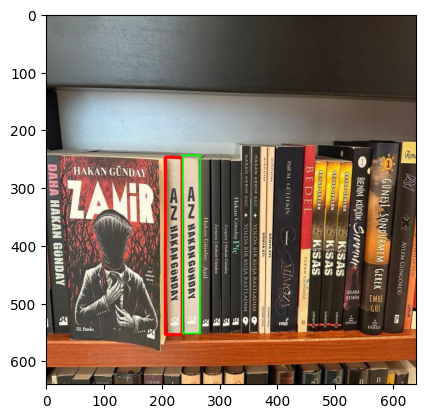

-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be computed. No instances detected.
-------- Processing model 4 --------
Homography could not be computed. No instances detected.
-------- Processing model 5 --------
Homography could not be computed. No instances detected.
-------- Processing model 6 --------
Homography could not be computed. No instances detected.
-------- Processing model 7 --------
Homography could not be computed. No instances detected.
-------- Processing model 8 --------
Homography could not be computed. No instances detected.
-------- Processing model 9 --------
Homography could not be computed. No instances detected.
-------- Processing model 10 --------
Homography could not be computed. No instances detected.
-------- Processing model 11 --------
Homography could not be computed. No instances detected.
-------- Processing model 12 --------
Homography could not

In [4]:
grayscale = False
crosscheck = False
lowe_ratio = 0.75
min_match_pct = 0.06
hyst_th = (0.55, 0.80)

for i in range(0, 29):
     print(f"--------------------------------- Processing scene {i} ---------------------------------")
     scene_path = f'./dataset/scenes/scene_{i}.jpg'
     for j in range(0, 22):
          print(f"-------- Processing model {j} --------")

          model_path = f'./dataset/models/model_{j}.png'
          
          main(model_path, scene_path, 
               grayscale=grayscale, 
               hysteresys_th=hyst_th, 
               min_match_pct=min_match_pct,
               cross_check=crosscheck, 
               lowe_ratio=lowe_ratio, 
               method=cv2.RANSAC, 
               ransacReprojThreshold=5.0, 
               similarity_measure=cv2.TM_CCOEFF_NORMED)